In [5]:
from langgraph.graph import StateGraph,START ,END
from typing import TypedDict,Literal
from langchain_ollama import ChatOllama
from pydantic import BaseModel,Field
import json




llm = ChatOllama(model='qwen2.5:0.5b-instruct',temperature=0.2,max_token=100)


class SentimentSchema(BaseModel):
    sentiment: Literal['positive','negative'] = Field(description='sentiment of the review')

class DiagnosisSchema(BaseModel):
    issue_type: str 
    tone: str 
    urgency: str

sentiment_returning_llm = llm.with_structured_output(SentimentSchema) 
diagnosis_returning_llm = llm.with_structured_output(DiagnosisSchema) 


class SentimentState(TypedDict):
    review: str
    sentiment: Literal['positive','negative']
    diagnosis: dict
    response: str 


def find_sentiment(state:SentimentState):
    prompt = f'find the sentiment of the following review - {state['review']}'
    res = sentiment_returning_llm.invoke(prompt)
    return {'sentiment' : res.sentiment}

def check_condition(state:SentimentState):
    if state['sentiment'] == 'positive':
        return 'positive'
    else:
        return 'negative'

def positive_response(state: SentimentState):
    prompt = f'write a warm thank you message in 3 lines to this review.\n {state['review']}. Also in last line kindly ask the user to give feedback on our website at GTindustries.com' 
    res = llm.invoke(prompt) 
    return {'response': res.content}

def run_diagnosis(state:SentimentState):
    prompt = f'Diagnose this following negative review and return issue_type , tone of the review and urgency.\n Review - {state['review']}'
    res = diagnosis_returning_llm.invoke(prompt)
    return {'diagnosis': res.model_dump()}

def negative_response(state:SentimentState):
    prompt = f'write a empathetic, helpful resolution 2 line response based on the review diagnosis. \n Review Diagnosis - {state['diagnosis']}'
    res = llm.invoke(prompt)
    return {'response':res.content}

graph = StateGraph(SentimentState)

graph.add_node('find_sentiment',find_sentiment)
graph.add_node('run_diagnosis',run_diagnosis)
graph.add_node('negative_response',negative_response)
graph.add_node('positive_response',positive_response)

graph.add_edge(START,'find_sentiment')
graph.add_conditional_edges('find_sentiment',check_condition,{'positive':'positive_response', 'negative':'run_diagnosis'})
graph.add_edge('run_diagnosis','negative_response')
graph.add_edge('negative_response',END)
graph.add_edge('positive_response',END)

workflow = graph.compile()

inital_state = {
    "review": 'this is a very bad phone, I want refund. Otherwise I will file a court case against your company.'
}
final_state = workflow.invoke(inital_state)
print(final_state)






{'review': 'this is a very bad phone, I want refund. Otherwise I will file a court case against your company.', 'sentiment': 'negative', 'diagnosis': {'issue_type': 'product', 'tone': 'critical', 'urgency': 'high'}, 'response': "I'm sorry to hear that! I understand how frustrating this must be for you. Please know that we're here to help and support you through this difficult time. Let's find a solution together, one step at a time."}


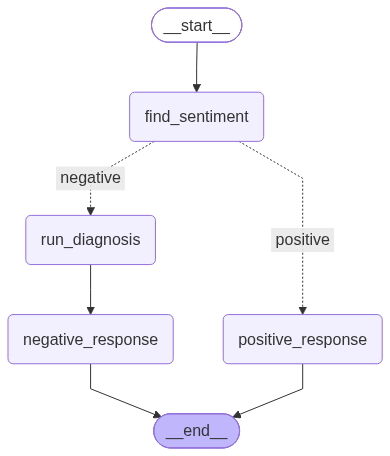

In [6]:
workflow